# Ajuste das distribuições de graus

Ajuste total (`xmin=1`) e da cauda (`xmin=None`) para os grafos de `raw` e `extend`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display

raiz = Path.cwd()
sys.path.insert(0, str(raiz if (raiz / "src").is_dir() else raiz.parent))

from src.complex_networks.config import DATA_DIR, RESULTS_DIR
from src.complex_networks.fitting import fit_degree_distributions
from src.complex_networks.io import load_edgelist

saida = RESULTS_DIR / "fitting"
escopos = {"total": 1, "cauda": None}

arquivos = [
    p for pasta in ("raw", "extend")
    for p in (DATA_DIR / pasta).glob("*.txt.gz") if p.is_file()
]

linhas = []
for arquivo in sorted(arquivos, key=lambda p: p.stat().st_size):
    origem = arquivo.parent.name
    instancia = arquivo.name.removesuffix(".txt.gz")
    print(f"{origem}/{instancia}", flush=True)

    try:
        G = load_edgelist(arquivo)
        G.remove_edges_from(list(nx.selfloop_edges(G)))
        G.remove_nodes_from(list(nx.isolates(G)))
    except Exception as erro:
        print(f"  Erro de leitura: {erro}")
        continue

    for escopo, xmin in escopos.items():
        try:
            resultado = fit_degree_distributions(G, xmin=xmin)
        except Exception as erro:
            print(f"  Erro no ajuste {escopo}: {erro}")
            continue
        linhas.extend(
            dict(origem=origem, instancia=instancia, escopo=escopo,
                 xmin=resultado["xmin"], n_fitted=resultado["n_fitted"],
                 fitted_percentage=resultado["fitted_percentage"], **modelo)
            for modelo in resultado["models"]
        )
    del G

if not linhas:
    raise ValueError("Nenhum ajuste disponível em raw ou extend.")

ajustes = pd.DataFrame(linhas)
ajustes.to_csv(saida / "ajustes_todos_modelos.csv", index=False)

raw/gemsec-Facebook-tvshow


/home/fernando/complex-networks/.venv/lib/python3.14/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/home/fernando/complex-networks/.venv/lib/python3.14/site-packages/scipy/optimize/_optimize.py:870: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


extend/p2p-Gnutella08


/home/fernando/complex-networks/.venv/lib/python3.14/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/home/fernando/complex-networks/.venv/lib/python3.14/site-packages/scipy/optimize/_optimize.py:870: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/home/fernando/complex-networks/.venv/lib/python3.14/site-packages/powerlaw/distributions.py:2792: RuntimeWarning: invalid value encountered in divide
  return likelihoods/norm
/home/fernando/complex-networks/.venv/lib/python3.14/site-packages/powerlaw/distributions.py:776: UserWarning: No valid fits found for distribution stretched_exponential.
  warnings.warn(f"No valid fits found for distribution {self.name}.")


extend/p2p-Gnutella09


/home/fernando/complex-networks/.venv/lib/python3.14/site-packages/powerlaw/distributions.py:808: UserWarning: Fitted parameters are very close to the edge of parameter ranges for distribution truncated_power_law; consider changing these ranges.
  warnings.warn(f'Fitted parameters are very close to the edge of parameter ranges for distribution {self.name}; consider changing these ranges.')
/home/fernando/complex-networks/.venv/lib/python3.14/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/home/fernando/complex-networks/.venv/lib/python3.14/site-packages/scipy/optimize/_optimize.py:870: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/home/fernando/complex-networks/.venv/lib/python3.14/site-packages/powerlaw/distributions.py:1091: RuntimeWarning: invalid value encountered in multiply
  likelihoods = f*C
/home/fernando/complex-networks/.venv/lib/python3.14/site-pac

... (90 outputs left out)

raw/twitch-gamers


/home/fernando/complex-networks/.venv/lib/python3.14/site-packages/powerlaw/distributions.py:808: UserWarning: Fitted parameters are very close to the edge of parameter ranges for distribution truncated_power_law; consider changing these ranges.
  warnings.warn(f'Fitted parameters are very close to the edge of parameter ranges for distribution {self.name}; consider changing these ranges.')
/home/fernando/complex-networks/.venv/lib/python3.14/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/home/fernando/complex-networks/.venv/lib/python3.14/site-packages/scipy/optimize/_optimize.py:870: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/home/fernando/complex-networks/.venv/lib/python3.14/site-packages/powerlaw/distributions.py:808: UserWarning: Fitted parameters are very close to the edge of parameter ranges for distribution exponential; consider changing these rang

raw/as-skitter


/home/fernando/complex-networks/.venv/lib/python3.14/site-packages/powerlaw/distributions.py:808: UserWarning: Fitted parameters are very close to the edge of parameter ranges for distribution truncated_power_law; consider changing these ranges.
  warnings.warn(f'Fitted parameters are very close to the edge of parameter ranges for distribution {self.name}; consider changing these ranges.')
/home/fernando/complex-networks/.venv/lib/python3.14/site-packages/powerlaw/distributions.py:1276: RuntimeWarning: divide by zero encountered in log
  return np.log(self.likelihoods(data))
/home/fernando/complex-networks/.venv/lib/python3.14/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/home/fernando/complex-networks/.venv/lib/python3.14/site-packages/scipy/optimize/_optimize.py:870: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/home/fernando/complex-networks/.venv/lib/pyt

## Distribuição escolhida

O menor AIC escolhe a família em cada recorte, levando em conta a verossimilhança
e o número de parâmetros. O ΔAIC é a diferença para o segundo colocado.
A concordância com a maior log-verossimilhança usa os recortes com pelo menos
dois candidatos válidos.

In [2]:
validos = ajustes.loc[
    ajustes["in_range"]
    & np.isfinite(ajustes["aic"])
    & np.isfinite(ajustes["log_likelihood"])
]

linhas = []
for (origem, instancia, escopo), grupo in validos.groupby(
    ["origem", "instancia", "escopo"], sort=False
):
    primeiro, *outros = grupo.sort_values("aic", kind="stable").to_dict("records")
    segundo = outros[0] if outros else {}
    linhas.append(dict(
        origem=origem, instancia=instancia, escopo=escopo,
        distribuicao_escolhida=primeiro["model"], parametros=primeiro["parameters"],
        segundo_modelo=segundo.get("model"),
        delta_aic_2o=segundo.get("aic", np.nan) - primeiro["aic"],
        aic=primeiro["aic"], log_likelihood=primeiro["log_likelihood"],
        ks=primeiro["ks"], xmin=primeiro["xmin"],
        n_fitted=primeiro["n_fitted"], fitted_percentage=primeiro["fitted_percentage"],
        aic_concorda_ll=primeiro["log_likelihood"] == grupo["log_likelihood"].max()
        if outros else None,
    ))

if not linhas:
    raise ValueError("Nenhum modelo válido para selecionar pelo AIC.")

escolhidas = pd.DataFrame(linhas)
escolhidas.to_csv(saida / "distribuicoes_escolhidas.csv", index=False)
display(escolhidas)

for escopo, grupo in escolhidas.groupby("escopo", sort=False):
    acordo = grupo["aic_concorda_ll"].dropna()
    if len(acordo):
        print(f"{escopo.title()}: AIC e log-verossimilhança concordaram em "
              f"{int(acordo.sum())}/{len(acordo)} casos ({acordo.mean():.1%}).")
    else:
        print(f"{escopo.title()}: não houve casos com dois candidatos válidos.")

,origem,instancia,escopo,distribuicao_escolhida,parametros,segundo_modelo,delta_aic_2o,aic,log_likelihood,ks,xmin,n_fitted,fitted_percentage,aic_concorda_ll
0,raw,gemsec-Facebook-tvshow,total,lognormal,"{'mu': 1.4785579534696227, 'sigma': 1.17536342...",stretched_exponential,78.107279,2.371805e+04,-1.185703e+04,0.007994,1,3892,100.000000,True
1,raw,gemsec-Facebook-tvshow,cauda,truncated_power_law,"{'alpha': 1.569423156202841, 'Lambda': 0.02383...",stretched_exponential,3.037342,4.012001e+03,-2.004001e+03,0.054530,17,528,13.566290,True
2,extend,p2p-Gnutella08,total,truncated_power_law,"{'alpha': 0.6816596435471328, 'Lambda': 0.0808...",stretched_exponential,50.330115,3.459213e+04,-1.729406e+04,0.093253,1,6301,100.000000,True
3,extend,p2p-Gnutella08,cauda,lognormal,"{'mu': -374.3947289567093, 'sigma': 10.0582075...",power_law,4.275659,8.721226e+03,-4.358613e+03,0.078707,11,1890,29.995239,True
4,extend,p2p-Gnutella09,total,truncated_power_law,"{'alpha': 0.7593945767000817, 'Lambda': 0.0751...",stretched_exponential,123.196085,4.379106e+04,-2.189353e+04,0.097993,1,8114,100.000000,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,raw,web-Google,cauda,power_law,{'alpha': 2.7251576451116755},truncated_power_law,2.000062,3.425561e+05,-1.712770e+05,0.005447,29,39063,4.460708,True
96,raw,twitch-gamers,total,lognormal,"{'mu': 3.395802597595768, 'sigma': 1.394589902...",stretched_exponential,25290.134716,1.730230e+06,-8.651132e+05,0.027855,1,168114,100.000000,True
97,raw,twitch-gamers,cauda,truncated_power_law,"{'alpha': 2.5225459968063273, 'Lambda': 1.3536...",power_law,1.046215,1.230941e+05,-6.154506e+04,0.007227,250,9141,5.437382,True
98,raw,as-skitter,total,lognormal,"{'mu': 1.528711446233154, 'sigma': 1.225014658...",stretched_exponential,296631.944954,1.065981e+07,-5.329901e+06,0.030023,1,1696415,100.000000,True


Total: AIC e log-verossimilhança concordaram em 50/50 casos (100.0%).
Cauda: AIC e log-verossimilhança concordaram em 39/50 casos (78.0%).


## Famílias escolhidas: frequência e matriz total × cauda

A matriz inclui os grafos com vencedor nos dois recortes. A diagonal conta os
que mantiveram a mesma família.

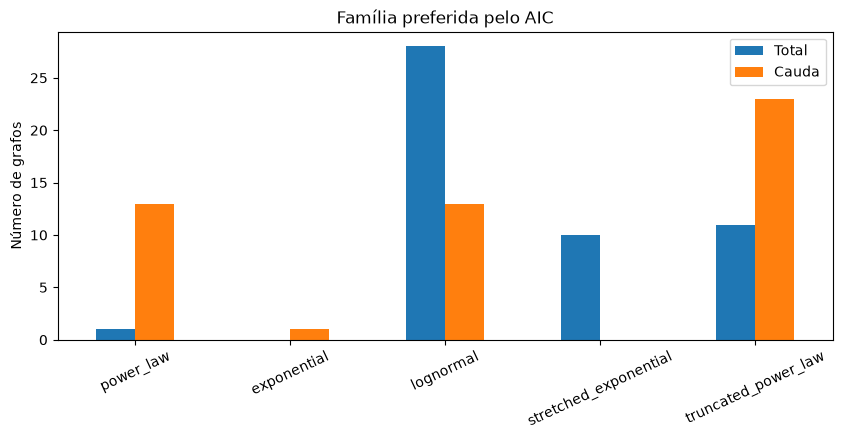

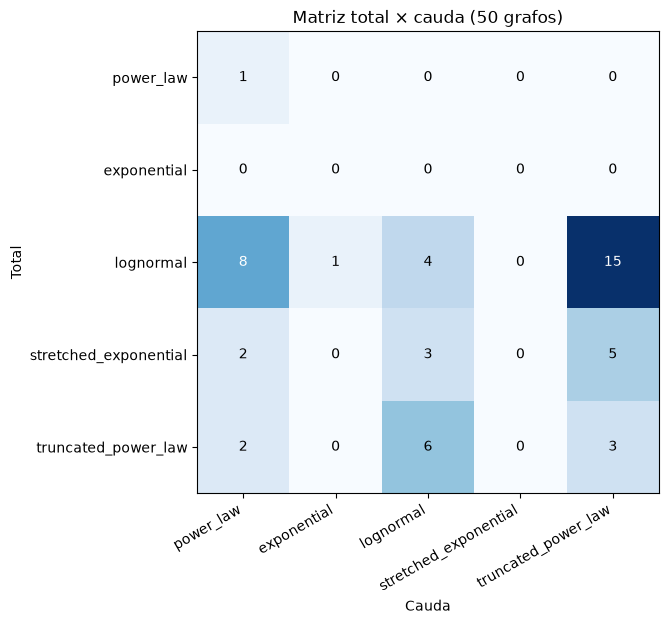

In [3]:
familias = ajustes["model"].drop_duplicates().tolist()

frequencias = pd.crosstab(escolhidas["distribuicao_escolhida"], escolhidas["escopo"])
frequencias = frequencias.reindex(index=familias, columns=escopos, fill_value=0)
ax = frequencias.rename(columns=str.title).plot.bar(figsize=(10, 4), rot=25)
ax.set(title="Família preferida pelo AIC", xlabel="", ylabel="Número de grafos")
ax.legend(title="")
ax.figure.savefig(saida / "familias_preferidas_aic.png", dpi=200, bbox_inches="tight")
plt.show()

pares = escolhidas.pivot(
    index=["origem", "instancia"], columns="escopo", values="distribuicao_escolhida"
).reindex(columns=escopos).dropna()
matriz = pd.crosstab(pares["total"], pares["cauda"]).reindex(
    index=familias, columns=familias, fill_value=0
).to_numpy()

fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(matriz, cmap="Blues", vmin=0)
for (i, j), n in np.ndenumerate(matriz):
    ax.text(j, i, n, ha="center", va="center",
            color="white" if n > matriz.max() / 2 else "black")
ax.set_xticks(range(len(familias)), familias, rotation=30, ha="right")
ax.set_yticks(range(len(familias)), familias)
ax.set(title=f"Matriz total × cauda ({len(pares)} grafos)", xlabel="Cauda", ylabel="Total")
fig.savefig(saida / "matriz_total_cauda.png", dpi=200, bbox_inches="tight")
plt.show()

## ΔAIC para o segundo e KS dos vencedores

O KS mede o maior afastamento entre as acumuladas e é mostrado em pontos percentuais.

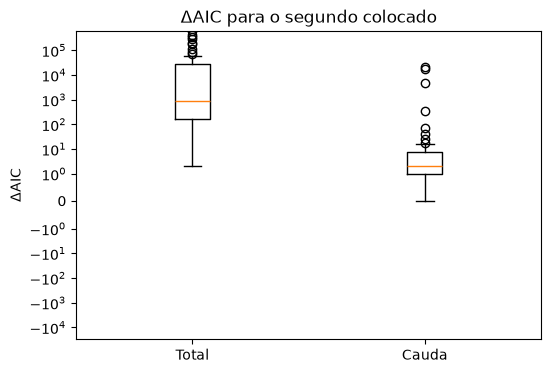

Total: mediana de 859 ΔAIC (n=50)
Cauda: mediana de 2 ΔAIC (n=50)


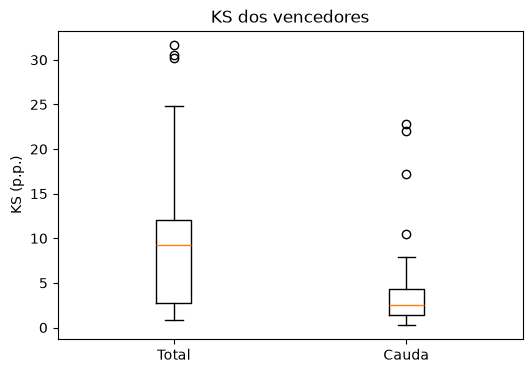

Total: mediana de 9.19 KS (p.p.) (n=50)
Cauda: mediana de 2.53 KS (p.p.) (n=50)


In [4]:
for coluna, fator, titulo, unidade, arquivo in [
    ("delta_aic_2o", 1, "ΔAIC para o segundo colocado", "ΔAIC", "boxplot_delta_aic.png"),
    ("ks", 100, "KS dos vencedores", "KS (p.p.)", "boxplot_ks.png"),
]:
    valores = [
        escolhidas.loc[escolhidas["escopo"].eq(escopo), coluna]
        .replace([np.inf, -np.inf], np.nan).dropna() * fator
        for escopo in escopos
    ]

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.boxplot(valores)
    ax.set_xticks([1, 2], ["Total", "Cauda"])
    ax.set(title=titulo, ylabel=unidade)
    if coluna == "delta_aic_2o":
        ax.set_yscale("symlog", linthresh=1)
    fig.savefig(saida / arquivo, dpi=200, bbox_inches="tight")
    plt.show()

    for escopo, dados in zip(escopos, valores):
        if len(dados):
            print(f"{escopo.title()}: mediana de {dados.median():.3g} {unidade} (n={len(dados)})")